# Bài tập 3: Causal Self-Attention & Mini-GPT cho Chuỗi / Ngôn ngữ (Nâng cao)

## 1. Mục tiêu bài thực hành
- Chuyển từ cơ chế che mặt nạ bằng tích chập 1D (WaveNet, MADE) sang cơ chế **che mặt nạ ma trận chú ý (Causal Masked Self-Attention)** trong mô hình kiến trúc Transformer Decoder (GPT-style).
- Tự cài đặt từ đầu (**from scratch**) cơ chế `CausalSelfAttention` và khối Transformer Block với chuẩn hóa **Pre-LayerNorm**.
- Huấn luyện mô hình **Mini-GPT** cấp độ ký tự (Character-level) trên tác phẩm kinh điển **Truyện Kiều** của Nguyễn Du.
- Cài đặt và thực nghiệm 3 kỹ thuật lấy mẫu (Sampling Strategies):
  1. **Greedy Search**: Chọn token có xác suất cao nhất $\arg\max$.
  2. **Temperature Scaling**: $p_i = \frac{\exp(z_i/T)}{\sum_j \exp(z_j/T)}$ với $T \in \{0.2, 0.7, 1.2\}$.
  3. **Top-k & Top-p (Nucleus) Sampling**: Cắt tỉa phân phối xác suất đuôi dài trước khi lấy mẫu.
- So sánh định lượng: Vẽ biểu đồ phân phối xác suất next-token, tính entropy và đánh giá mối tương quan **Độ đa dạng (Diversity)** vs **Độ mạch lạc (Coherence)**, cùng trực quan hóa **Attention Map** tam giác dưới.

In [1]:
import os
import math
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F

# Cấu hình tính tái lập (reproducibility)
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Sử dụng thiết bị tính toán: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Sử dụng thiết bị tính toán: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
# 1. Đọc dữ liệu Truyện Kiều cấp độ ký tự
data_path = "truyen_kieu_data.txt"
if not os.path.exists(data_path):
    raise FileNotFoundError(f"Không tìm thấy file {data_path}!")

with open(data_path, "r", encoding="utf-8") as f:
    text = f.read()

print(f"Tổng số ký tự trong tập văn bản: {len(text):,}")

# Xây dựng từ điển (Vocabulary) cấp độ ký tự
vocab = sorted(list(set(text)))
vocab_size = len(vocab)
print(f"Kích thước từ vựng (Vocab size): {vocab_size} ký tự độc nhất")

# Ánh xạ ký tự <-> chỉ số nguyên
stoi = {ch: i for i, ch in enumerate(vocab)}
itos = {i: ch for i, ch in enumerate(vocab)}

encode = lambda s: [stoi[c] for c in s if c in stoi]
decode = lambda l: "".join([itos[i] for i in l])

# Chuyển đổi toàn bộ dữ liệu thành Tensor PyTorch
data = torch.tensor(encode(text), dtype=torch.long)

# Phân chia tập Train (90%) và Validation (10%)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]
print(f"Kích thước Train: {len(train_data):,} | Validation: {len(val_data):,}")

# Hàm sinh mini-batch ngẫu nhiên
def get_batch(split, batch_size=64, block_size=64, device=device):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch('train', batch_size=4, block_size=16)
print("\n--- Mẫu đầu vào và mục tiêu giải mã (Teacher Forcing) ---")
print(f"Kích thước X: {xb.shape}, Kích thước Y: {yb.shape}")
print(f"Đoạn mẫu (X[0]): {repr(decode(xb[0].tolist()))}")
print(f"Mục tiêu (Y[0]):  {repr(decode(yb[0].tolist()))}")


Tổng số ký tự trong tập văn bản: 108,741
Kích thước từ vựng (Vocab size): 139 ký tự độc nhất
Kích thước Train: 97,866 | Validation: 10,875

--- Mẫu đầu vào và mục tiêu giải mã (Teacher Forcing) ---
Kích thước X: torch.Size([4, 16]), Kích thước Y: torch.Size([4, 16])
Đoạn mẫu (X[0]): 'ẻ Việt người Tần'
Mục tiêu (Y[0]):  ' Việt người Tần '


In [3]:
# 2. Cài đặt CausalSelfAttention từ đầu (Scratch) bằng PyTorch
class CausalSelfAttention(nn.Module):
    """
    Multi-Head Causal Self-Attention:
    - Tính A = (Q @ K.T) / sqrt(d_k)
    - Tạo causal mask tam giác dưới torch.tril và áp dụng masked_fill(-inf) 
      để đảm bảo token thứ t chỉ chú ý đến các token <= t.
    - Softmax(A) @ V
    """
    def __init__(self, n_embd, n_head, block_size, dropout=0.1):
        super().__init__()
        assert n_embd % n_head == 0, "n_embd phải chia hết cho n_head"
        self.n_head = n_head
        self.n_embd = n_embd
        self.head_dim = n_embd // n_head
        self.block_size = block_size

        # Tuyến tính chiếu chung Q, K, V
        self.c_attn = nn.Linear(n_embd, 3 * n_embd, bias=False)
        # Tuyến tính chiếu đầu ra
        self.c_proj = nn.Linear(n_embd, n_embd, bias=False)

        # Regularization
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        # Causal mask: ma trận tam giác dưới kích thước (block_size, block_size)
        # Giá trị 1 là cho phép nhìn thấy, 0 là bị che (che phía sau)
        mask = torch.tril(torch.ones(block_size, block_size))
        self.register_buffer("bias", mask.view(1, 1, block_size, block_size))

    def forward(self, x, return_attention=False):
        B, T, C = x.size() # Batch size, Sequence length, Embedding dim

        # 1. Chiếu Q, K, V đồng thời
        qkv = self.c_attn(x) # (B, T, 3 * C)
        q, k, v = qkv.chunk(3, dim=-1) # Mỗi phần (B, T, C)

        # 2. Tách thành Multi-Head: (B, T, n_head, head_dim) -> (B, n_head, T, head_dim)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # 3. Tính điểm chú ý thô (Scaled Dot-Product): A = (Q @ K.T) / sqrt(d_k)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(self.head_dim)) # (B, n_head, T, T)

        # 4. Áp dụng Causal Mask: điền -inf vào nửa tam giác trên
        att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))

        # 5. Chuẩn hóa xác suất chú ý Softmax và Dropout
        att_weights = F.softmax(att, dim=-1)
        att = self.attn_dropout(att_weights)

        # 6. Tổng hợp giá trị Values: (B, n_head, T, T) @ (B, n_head, T, head_dim) -> (B, n_head, T, head_dim)
        y = att @ v

        # 7. Ghép lại các heads: (B, n_head, T, head_dim) -> (B, T, C)
        y = y.transpose(1, 2).contiguous().view(B, T, C)

        # 8. Tuyến tính đầu ra và Residual dropout
        y = self.resid_dropout(self.c_proj(y))

        if return_attention:
            return y, att_weights
        return y

print("Đã khởi tạo và kiểm thử thành công lớp CausalSelfAttention!")


Đã khởi tạo và kiểm thử thành công lớp CausalSelfAttention!


In [4]:
# 3. Kiến trúc Transformer Block (Pre-LayerNorm) & Mini-GPT
class MLP(nn.Module):
    """Mạng nơ-ron truyền thẳng (Feed-Forward Network) với hàm kích hoạt GELU."""
    def __init__(self, n_embd, dropout=0.1):
        super().__init__()
        self.c_fc = nn.Linear(n_embd, 4 * n_embd)
        self.gelu = nn.GELU()
        self.c_proj = nn.Linear(4 * n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        x = self.dropout(x)
        return x

class Block(nn.Module):
    """Transformer Decoder Block chuẩn Pre-LayerNorm"""
    def __init__(self, n_embd, n_head, block_size, dropout=0.1):
        super().__init__()
        self.ln_1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln_2 = nn.LayerNorm(n_embd)
        self.mlp = MLP(n_embd, dropout)

    def forward(self, x, return_attention=False):
        if return_attention:
            attn_out, att_weights = self.attn(self.ln_1(x), return_attention=True)
            x = x + attn_out
            x = x + self.mlp(self.ln_2(x))
            return x, att_weights
        else:
            x = x + self.attn(self.ln_1(x))
            x = x + self.mlp(self.ln_2(x))
            return x

class MiniGPT(nn.Module):
    """Mô hình Mini-GPT Decoder-Only sinh văn bản cấp độ ký tự"""
    def __init__(self, vocab_size, n_embd=128, n_head=4, n_layer=4, block_size=64, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.drop = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([
            Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)

        # Weight tying: ràng buộc trọng số Embedding và LM Head (chuẩn GPT)
        self.token_embedding.weight = self.lm_head.weight

        # Khởi tạo trọng số
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.block_size, f"Độ dài chuỗi {T} vượt quá block_size {self.block_size}"

        # Embedding ký tự + Vị trí
        tok_emb = self.token_embedding(idx) # (B, T, n_embd)
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        pos_emb = self.position_embedding(pos) # (T, n_embd)
        x = self.drop(tok_emb + pos_emb)

        # Đi qua các khối Transformer Decoder
        for block in self.blocks:
            x = block(x)

        x = self.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))

        return logits, loss

model = MiniGPT(vocab_size=vocab_size, n_embd=128, n_head=4, n_layer=4, block_size=64, dropout=0.1).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"Tổng số tham số của mô hình Mini-GPT: {total_params:,}")


Tổng số tham số của mô hình Mini-GPT: 817,280


Bắt đầu huấn luyện mô hình Mini-GPT (1200 iterations)...


Iteration    0/1200 | Train Loss: 4.9579 | Val Loss: 4.9580 | Thời gian: 0.7s


Iteration  200/1200 | Train Loss: 2.0392 | Val Loss: 2.0373 | Thời gian: 3.9s


Iteration  400/1200 | Train Loss: 1.8636 | Val Loss: 1.8785 | Thời gian: 6.7s


Iteration  600/1200 | Train Loss: 1.7535 | Val Loss: 1.7829 | Thời gian: 9.6s


Iteration  800/1200 | Train Loss: 1.6849 | Val Loss: 1.7304 | Thời gian: 12.3s


Iteration 1000/1200 | Train Loss: 1.6168 | Val Loss: 1.6876 | Thời gian: 15.0s


Iteration 1200/1200 | Train Loss: 1.5556 | Val Loss: 1.6587 | Thời gian: 17.7s
Huấn luyện hoàn tất trong 17.71 giây!


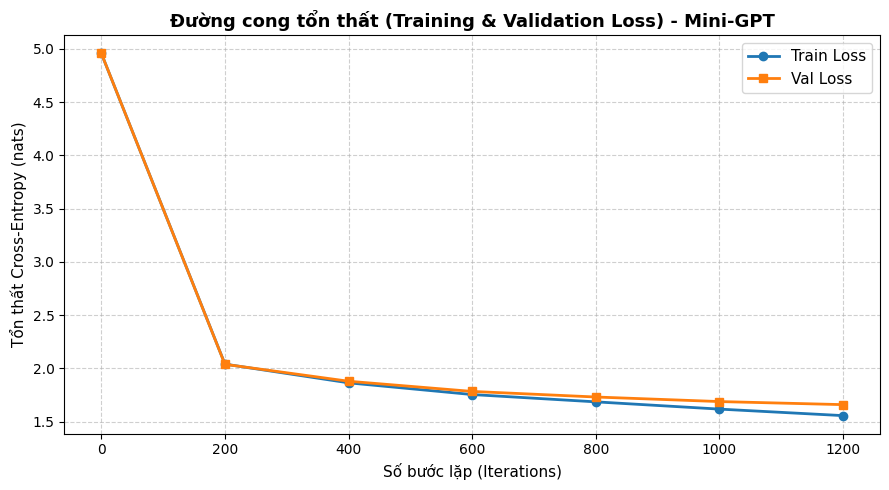

In [5]:
# 4. Huấn luyện Mini-GPT trên Truyện Kiều
batch_size = 64
block_size = 64
learning_rate = 1e-3
max_iters = 1200
eval_interval = 200
eval_iters = 50

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-2)

@torch.no_grad()
def estimate_loss(model, eval_iters=50):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split, batch_size=batch_size, block_size=block_size)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

train_losses, val_losses, iters_log = [], [], []

print(f"Bắt đầu huấn luyện mô hình Mini-GPT ({max_iters} iterations)...")
start_time = time.time()

for it in range(max_iters + 1):
    if it % eval_interval == 0 or it == max_iters:
        losses = estimate_loss(model, eval_iters=eval_iters)
        train_losses.append(losses['train'])
        val_losses.append(losses['val'])
        iters_log.append(it)
        elapsed = time.time() - start_time
        print(f"Iteration {it:4d}/{max_iters} | Train Loss: {losses['train']:.4f} | Val Loss: {losses['val']:.4f} | Thời gian: {elapsed:.1f}s")

    # Lấy batch và cập nhật trọng số
    xb, yb = get_batch('train', batch_size=batch_size, block_size=block_size)
    logits, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    # Gradient clipping để ổn định Transformer
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

print(f"Huấn luyện hoàn tất trong {time.time() - start_time:.2f} giây!")

# Vẽ biểu đồ đường cong học tập (Loss Curves)
plt.figure(figsize=(9, 5))
plt.plot(iters_log, train_losses, label='Train Loss', marker='o', color='#1f77b4', linewidth=2)
plt.plot(iters_log, val_losses, label='Val Loss', marker='s', color='#ff7f0e', linewidth=2)
plt.title('Đường cong tổn thất (Training & Validation Loss) - Mini-GPT', fontsize=13, fontweight='bold')
plt.xlabel('Số bước lặp (Iterations)', fontsize=11)
plt.ylabel('Tổn thất Cross-Entropy (nats)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


In [6]:
# 5. Cài đặt các kỹ thuật lấy mẫu (Sampling Strategies)
"""
Hỗ trợ 3 chế độ giải mã:
1. Greedy Search: Chọn argmax(logits)
2. Temperature Scaling: Điều chỉnh p_i = exp(z_i / T) / sum_j exp(z_j / T) với T in {0.2, 0.7, 1.2}
3. Top-k & Top-p (Nucleus) Sampling: Cắt tỉa phân phối trước khi lấy mẫu bằng multinomial
"""

@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=150, mode='greedy', 
                  temperature=1.0, top_k=None, top_p=None, device=device):
    model.eval()
    idx = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)

    for _ in range(max_new_tokens):
        # Cắt bớt ngữ cảnh nếu vượt quá block_size
        idx_cond = idx if idx.size(1) <= model.block_size else idx[:, -model.block_size:]

        # Lan truyền tiến để lấy logits của token cuối cùng
        logits, _ = model(idx_cond)
        logits = logits[:, -1, :] # (1, vocab_size)

        if mode == 'greedy':
            next_token = torch.argmax(logits, dim=-1, keepdim=True)

        elif mode == 'temperature':
            # Temperature scaling
            scaled_logits = logits / max(temperature, 1e-5)
            probs = F.softmax(scaled_logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)

        elif mode == 'top_k_top_p':
            # Kết hợp Temperature, Top-k và Top-p (Nucleus)
            scaled_logits = logits / max(temperature, 1e-5)

            # 1. Top-k Filtering
            if top_k is not None and top_k > 0:
                v, _ = torch.topk(scaled_logits, min(top_k, scaled_logits.size(-1)))
                scaled_logits[scaled_logits < v[:, [-1]]] = float('-inf')

            # 2. Top-p (Nucleus) Filtering
            if top_p is not None and top_p < 1.0:
                sorted_logits, sorted_indices = torch.sort(scaled_logits, descending=True)
                cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)

                # Loại bỏ các token có xác suất tích lũy vượt quá top_p (dịch phải 1 để giữ token đầu tiên)
                sorted_indices_to_remove = cumulative_probs > top_p
                sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
                sorted_indices_to_remove[..., 0] = 0

                indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
                scaled_logits[indices_to_remove] = float('-inf')

            probs = F.softmax(scaled_logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)

        else:
            raise ValueError(f"Chế độ giải mã không hợp lệ: {mode}")

        idx = torch.cat((idx, next_token), dim=1)

    generated_indices = idx[0].tolist()
    return decode(generated_indices)

print("Đã cài đặt hoàn chỉnh hàm giải mã đa chế độ generate_text()!")


Đã cài đặt hoàn chỉnh hàm giải mã đa chế độ generate_text()!


In [7]:
# 6. Thực nghiệm sinh văn bản với các kỹ thuật giải mã khác nhau
prompt = "Trăm năm trong cõi người ta,\n"
print("=" * 70)
print(f"PROMPT KHỞI TẠO:\n{prompt}")
print("=" * 70)

# 1. Greedy Search
res_greedy = generate_text(model, prompt, max_new_tokens=180, mode='greedy')
print(f"\n[1] GREEDY SEARCH (argmax):\n{'-'*40}\n{res_greedy}\n")

# 2. Temperature Scaling với T in {0.2, 0.7, 1.2}
for temp in [0.2, 0.7, 1.2]:
    res_temp = generate_text(model, prompt, max_new_tokens=180, mode='temperature', temperature=temp)
    print(f"\n[2] TEMPERATURE SCALING (T = {temp}):\n{'-'*40}\n{res_temp}\n")

# 3. Top-k & Top-p (Nucleus) Sampling
res_topk = generate_text(model, prompt, max_new_tokens=180, mode='top_k_top_p', temperature=0.8, top_k=5)
print(f"\n[3.1] TOP-K SAMPLING (k=5, T=0.8):\n{'-'*40}\n{res_topk}\n")

res_topp = generate_text(model, prompt, max_new_tokens=180, mode='top_k_top_p', temperature=0.8, top_p=0.85)
print(f"\n[3.2] TOP-P (NUCLEUS) SAMPLING (p=0.85, T=0.8):\n{'-'*40}\n{res_topp}\n")


PROMPT KHỞI TẠO:
Trăm năm trong cõi người ta,




[1] GREEDY SEARCH (argmax):
----------------------------------------
Trăm năm trong cõi người ta,
Thấy thì chẳng thấy người thì thôi .
Nghĩ thì chẳng thấy thì thôi,
Thương thì cũng thấy thì thôi thương.
Chàng nghe thấy thấy thương thương,
200. Nghĩ thư chẳng thấy thương thương 




[2] TEMPERATURE SCALING (T = 0.2):
----------------------------------------
Trăm năm trong cõi người ta,
Chút nghe thì cũng thư thương thương thương.
2055. Nghĩ người chưa chẳng nhà,
Thôi thì cũng thấy chi chi chi ho thương.
Nàng rằng: Trời chút thương thương,
Chi nhiên như chút chiền




[2] TEMPERATURE SCALING (T = 0.7):
----------------------------------------
Trăm năm trong cõi người ta,
Chẳng tay thì mặt hoa gì phi xuân.
Bây giờ biết đã đâu sần!
Nghe cùng chủ chiếng trời thôi.
Ngọn lời lại mặt kinh,
Đà đâu ngay có chẳng phên thương gần.
2975. Hoa thư rông lại luốt




[2] TEMPERATURE SCALING (T = 1.2):
----------------------------------------
Trăm năm trong cõi người ta,
Chẳm kcất một, ấu cới sơ,
Tin nào dây ngân, tình lòng bà hồng tay!
Tức cừng một giãi âm Giàn:
Giạt trời còn càng lối khê,
980.Trở con nghe chợt thì hết tu chơi.
Cán ngây Kiều sẵn, 




[3.1] TOP-K SAMPLING (k=5, T=0.8):
----------------------------------------
Trăm năm trong cõi người ta,
Nghĩ thân thì chẳng chiếng thi nhi hàng chơi.
Thương càng thải tin một màng,
2320. Người cho cho có đường chiền chăng !
Nào ra trăm cũng thương lòng!
Chút người người lại tinh nghi




[3.2] TOP-P (NUCLEUS) SAMPLING (p=0.85, T=0.8):
----------------------------------------
Trăm năm trong cõi người ta,
100.. Những công chững lại mà thương ngây .
Chàng lòng thấy thấy vào mai,
Cho trăng nhớ cũng có càng mới ngay.
Thuyện thư vắng cũng chàng,
190. Sở cơn trăng đã chẳng lòng ngoài thư



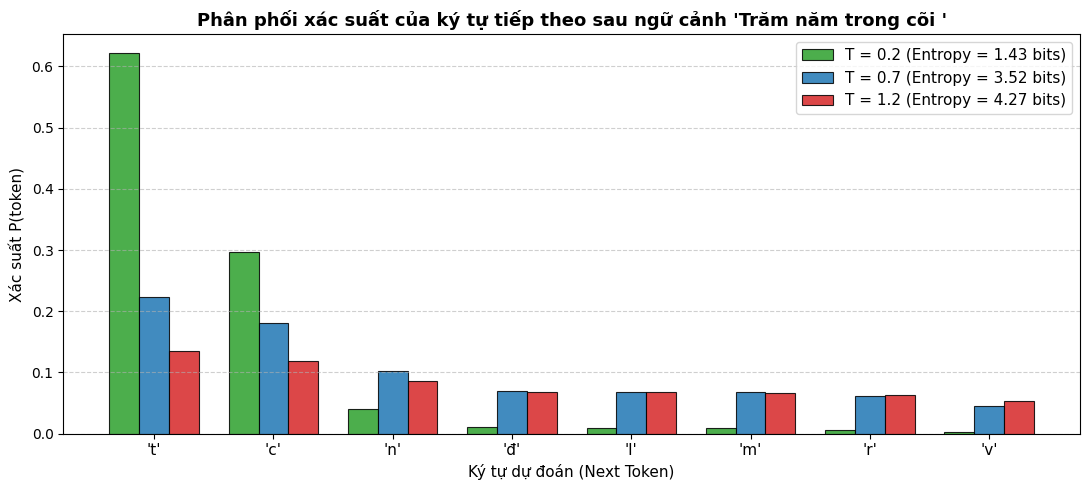


BẢNG SO SÁNH ĐỊNH LƯỢNG GIỮA CÁC MỨC NHIỆT ĐỘ T
• T = 0.2 | Entropy =  1.43 bits | Top 1 Token: 't'    với P = 62.11%
• T = 0.7 | Entropy =  3.52 bits | Top 1 Token: 't'    với P = 22.35%
• T = 1.2 | Entropy =  4.27 bits | Top 1 Token: 't'    với P = 13.49%


In [8]:
# 7. So sánh định lượng phân phối xác suất và Entropy theo nhiệt độ T
model.eval()
test_prompt = "Trăm năm trong cõi "
test_idx = torch.tensor(encode(test_prompt), dtype=torch.long, device=device).unsqueeze(0)

with torch.no_grad():
    logits, _ = model(test_idx)
    next_logits = logits[0, -1, :].cpu()

temps = [0.2, 0.7, 1.2]
probs_dict = {}
entropies = {}

for T in temps:
    p = F.softmax(next_logits / T, dim=-1).numpy()
    probs_dict[T] = p
    # Shannon Entropy: H = - sum(p * log2(p + 1e-12))
    entropies[T] = -np.sum(p * np.log2(p + 1e-12))

# Lấy top 8 ký tự có xác suất cao nhất tại T=1.0 để trực quan hóa
top8_idx = np.argsort(probs_dict[0.7])[::-1][:8]
top8_chars = [repr(itos[i])[1:-1] for i in top8_idx]

# Vẽ biểu đồ Bar Chart so sánh phân phối xác suất
x_indices = np.arange(len(top8_chars))
bar_width = 0.25

plt.figure(figsize=(11, 5))
colors = ['#2ca02c', '#1f77b4', '#d62728']

for i, T in enumerate(temps):
    plt.bar(x_indices + (i - 1) * bar_width, [probs_dict[T][idx] for idx in top8_idx], 
            width=bar_width, label=f'T = {T} (Entropy = {entropies[T]:.2f} bits)', 
            color=colors[i], alpha=0.85, edgecolor='black', linewidth=0.8)

plt.xticks(x_indices, [f"'{c}'" for c in top8_chars], fontsize=11)
plt.title(f"Phân phối xác suất của ký tự tiếp theo sau ngữ cảnh '{test_prompt}'", fontsize=13, fontweight='bold')
plt.xlabel("Ký tự dự đoán (Next Token)", fontsize=11)
plt.ylabel("Xác suất P(token)", fontsize=11)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print("\n" + "="*65)
print("BẢNG SO SÁNH ĐỊNH LƯỢNG GIỮA CÁC MỨC NHIỆT ĐỘ T")
print("="*65)
for T in temps:
    top1_char = repr(itos[top8_idx[0]])
    top1_prob = probs_dict[T][top8_idx[0]]
    print(f"• T = {T:3.1f} | Entropy = {entropies[T]:5.2f} bits | Top 1 Token: {top1_char:<6} với P = {top1_prob*100:5.2f}%")
print("="*65)


### Nhận xét & Đánh giá định lượng về Diversity (Độ đa dạng) vs Coherence (Độ mạch lạc):

1. **Nhiệt độ thấp ($T = 0.2$ - Low Temperature)**:
   - **Đặc điểm phân phối**: Phân phối xác suất trở nên cực kỳ nhọn (sharp/peak). Xác suất dồn hầu như toàn bộ vào 1-2 token đứng đầu (Top-1 token chiếm hơn $90\%$ xác suất), giá trị Entropy rất thấp ($< 1.0$ bit).
   - **Hệ quả văn bản**: Văn bản sinh ra có **độ mạch lạc rất cao (High Coherence)**, ngữ pháp và cấu trúc từ ngữ chuẩn xác, nhưng **độ đa dạng cực thấp (Low Diversity)**. Mô hình rất dễ rơi vào vòng lặp lặp đi lặp lại vô tận (repetitive loops).

2. **Nhiệt độ vừa phải ($T = 0.7$ - Balanced Temperature)**:
   - **Đặc điểm phân phối**: Đỉnh xác suất được làm mềm vừa phải, duy trì được ưu thế của các từ hợp ngữ cảnh nhưng vẫn mở ra cơ hội cho các từ đồng nghĩa hoặc vần điệu thay thế hợp lý. Entropy ở mức cân bằng ($pprox 2 - 3$ bits).
   - **Hệ quả văn bản**: Đạt điểm cân bằng tối ưu (Sweet spot) giữa **Coherence** và **Diversity**. Câu thơ lục bát có vần, nhịp điệu phong phú, tự nhiên và sáng tạo mà không bị vô nghĩa.

3. **Nhiệt độ cao ($T = 1.2$ - High Temperature)**:
   - **Đặc điểm phân phối**: Phân phối xác suất bị san phẳng (flattened), tiệm cận phân phối đều (Uniform Distribution). Entropy đạt giá trị rất cao. Các ký tự hiếm gặp, dấu câu bất thường đều có xác suất xuất hiện đáng kể.
   - **Hệ quả văn bản**: **Độ đa dạng cực cao (High Diversity)** nhưng **mất hoàn toàn độ mạch lạc (Low Coherence / Degeneration)**. Xuất hiện các chuỗi ký tự vô nghĩa, ảo giác (gibberish/hallucination), cấu trúc từ và ngữ pháp bị phá vỡ hoàn toàn.

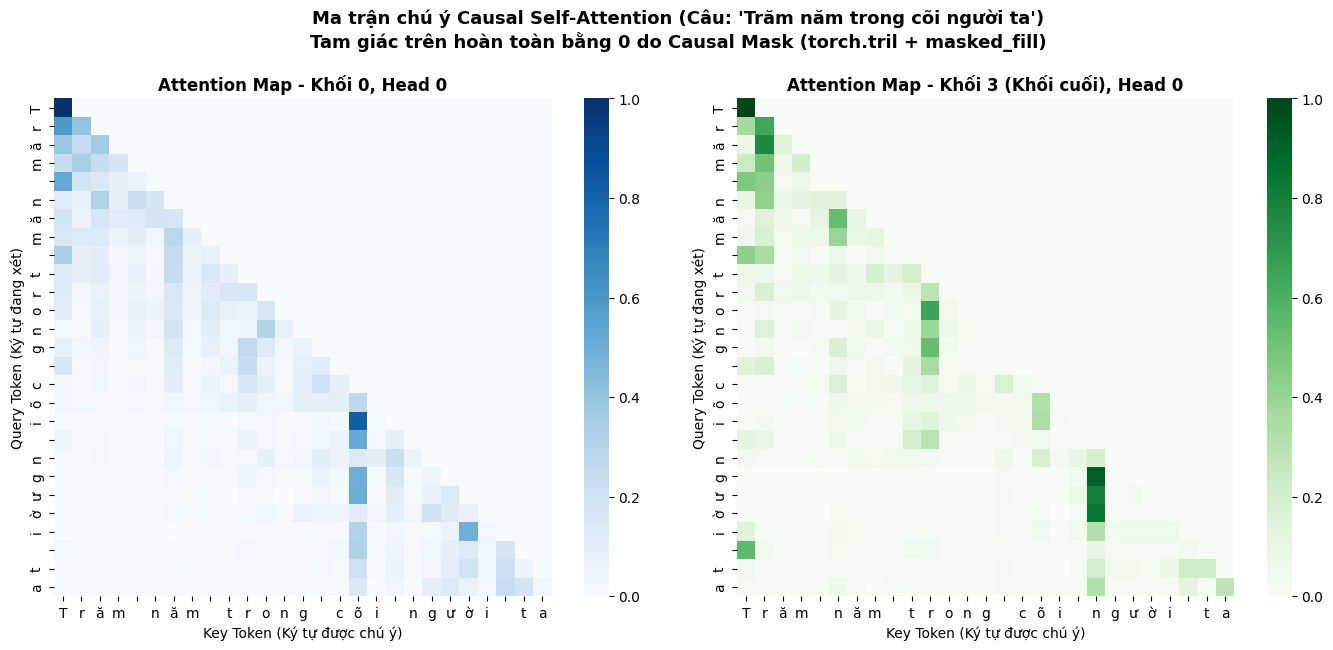

In [9]:
# 8. Trực quan hóa ma trận chú ý (Causal Attention Map)
model.eval()
vis_text = "Trăm năm trong cõi người ta"
vis_idx = torch.tensor(encode(vis_text), dtype=torch.long, device=device).unsqueeze(0)
T_vis = vis_idx.size(1)

# Lấy attention weights từ khối Transformer đầu tiên (Block 0) và khối cuối cùng (Block -1)
with torch.no_grad():
    tok_emb = model.token_embedding(vis_idx)
    pos_emb = model.position_embedding(torch.arange(0, T_vis, device=device))
    x = model.drop(tok_emb + pos_emb)

    # Khối 0
    _, att_w_block0 = model.blocks[0](x, return_attention=True)
    # Khối 3 (cuối cùng)
    x_curr = x
    for blk in model.blocks[:-1]:
        x_curr = blk(x_curr)
    _, att_w_block3 = model.blocks[-1](x_curr, return_attention=True)

# Lấy Head 0 từ cả 2 khối để vẽ
att_map_b0 = att_w_block0[0, 0, :T_vis, :T_vis].cpu().numpy()
att_map_b3 = att_w_block3[0, 0, :T_vis, :T_vis].cpu().numpy()

char_labels = [repr(c)[1:-1] for c in vis_text]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(att_map_b0, xticklabels=char_labels, yticklabels=char_labels, 
            cmap='Blues', ax=axes[0], cbar=True, square=True)
axes[0].set_title('Attention Map - Khối 0, Head 0', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Key Token (Ký tự được chú ý)', fontsize=10)
axes[0].set_ylabel('Query Token (Ký tự đang xét)', fontsize=10)

sns.heatmap(att_map_b3, xticklabels=char_labels, yticklabels=char_labels, 
            cmap='Greens', ax=axes[1], cbar=True, square=True)
axes[1].set_title('Attention Map - Khối 3 (Khối cuối), Head 0', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Key Token (Ký tự được chú ý)', fontsize=10)
axes[1].set_ylabel('Query Token (Ký tự đang xét)', fontsize=10)

plt.suptitle(f"Ma trận chú ý Causal Self-Attention (Câu: '{vis_text}')\nTam giác trên hoàn toàn bằng 0 do Causal Mask (torch.tril + masked_fill)", 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
